In [1]:
# Install required libraries
!pip install pandas numpy matplotlib seaborn scipy

# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats

# Set graph style
sns.set_style("whitegrid")

print("Python environment is ready!")

Python environment is ready!


#Superstore

In [3]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

csv_path = Path("Sample - Superstore.csv")
df = pd.read_csv(csv_path, encoding="cp1252", dtype={"Postal Code": "string"})
df["Order Date"] = pd.to_datetime(df["Order Date"], format="%m/%d/%Y")
df["Ship Date"] = pd.to_datetime(df["Ship Date"], format="%m/%d/%Y")
df["Month"] = df["Order Date"].dt.to_period("M").dt.to_timestamp()
df["Shipping Days"] = (df["Ship Date"] - df["Order Date"]).dt.days
df["Discount (%)"] = 100 * df["Discount"]
df["Loss"] = df["Profit"] < 0
df["Discount Band"] = pd.cut(
    df["Discount (%)"], [-1, 0, 20, 40, 100],
    labels=["0%", ">0–20%", ">20–40%", ">40%"]
)
sns.set_theme(style="whitegrid")
print(f"Loaded {len(df):,} order lines across {df['Order ID'].nunique():,} unique orders.")
print(f"Order dates: {df['Order Date'].min():%Y-%m-%d} to {df['Order Date'].max():%Y-%m-%d}")

Loaded 9,994 order lines across 5,009 unique orders.
Order dates: 2014-01-03 to 2017-12-30


#Horizontal Bar

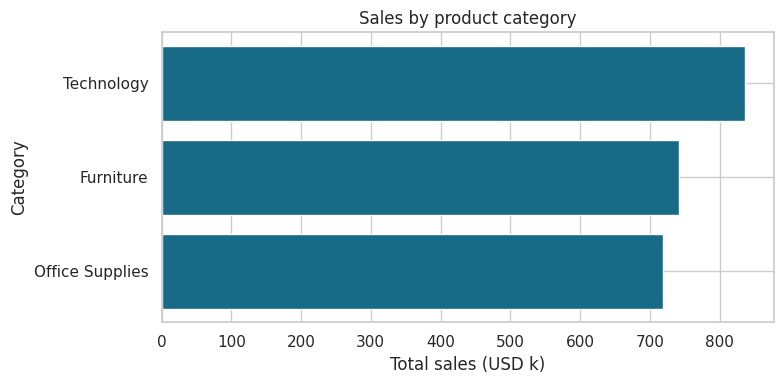

In [4]:
category_sales = df.groupby("Category")["Sales"].sum().sort_values()
plt.figure(figsize=(8, 4))
plt.barh(category_sales.index, category_sales / 1000, color="#176B87")
plt.xlabel("Total sales (USD k)")
plt.ylabel("Category")
plt.title("Sales by product category")

plt.tight_layout()
plt.show()

#Line · Monthly unique orders

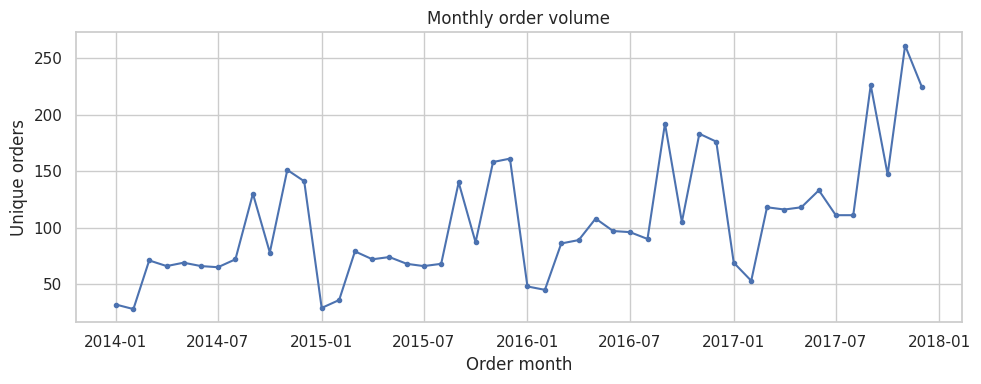

In [5]:
monthly_orders = df.groupby("Month")["Order ID"].nunique()
plt.figure(figsize=(10, 4))
plt.plot(monthly_orders.index, monthly_orders, marker="o", markersize=3)
plt.xlabel("Order month")
plt.ylabel("Unique orders")
plt.title("Monthly order volume")

plt.tight_layout()
plt.show()

#Stacked area · Monthly sales mix

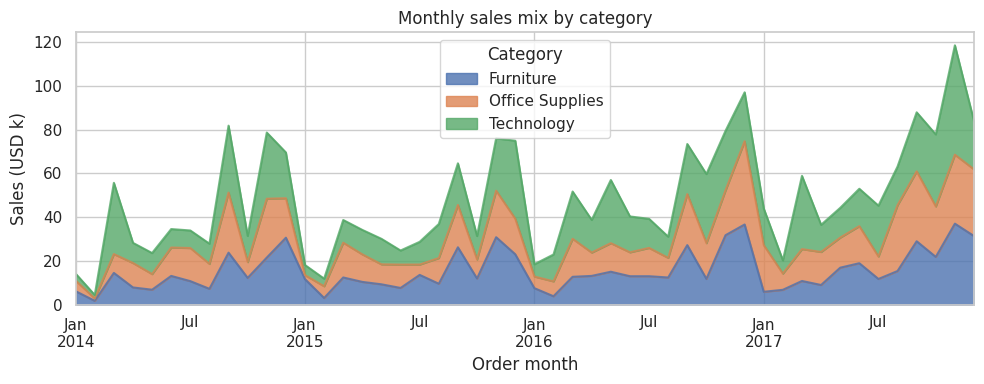

In [6]:
monthly_sales = df.pivot_table(
    index="Month", columns="Category", values="Sales", aggfunc="sum", fill_value=0
)
ax = (monthly_sales / 1000).plot(kind="area", alpha=0.8, figsize=(10, 4))
ax.set(xlabel="Order month", ylabel="Sales (USD k)", title="Monthly sales mix by category")

plt.tight_layout()
plt.show()

#Histogram · Sales per order line

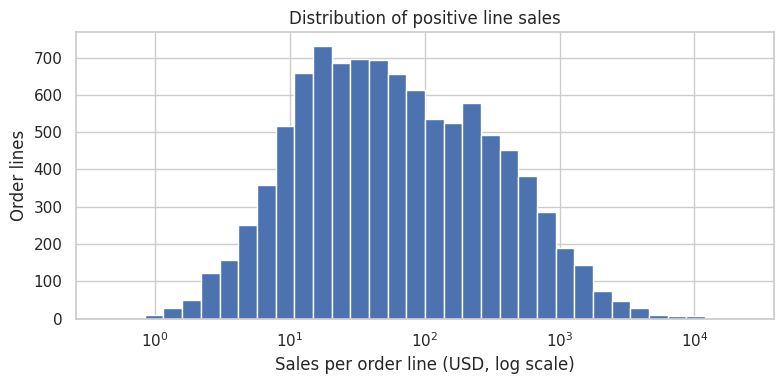

In [7]:
sales = df.loc[df["Sales"] > 0, "Sales"]
bins = np.geomspace(sales.min(), sales.max(), 35)
plt.figure(figsize=(8, 4))
plt.hist(sales, bins=bins, edgecolor="white")
plt.xscale("log")
plt.xlabel("Sales per order line (USD, log scale)")
plt.ylabel("Order lines")
plt.title("Distribution of positive line sales")

plt.tight_layout()
plt.show()

#Scatter · Discount versus profit

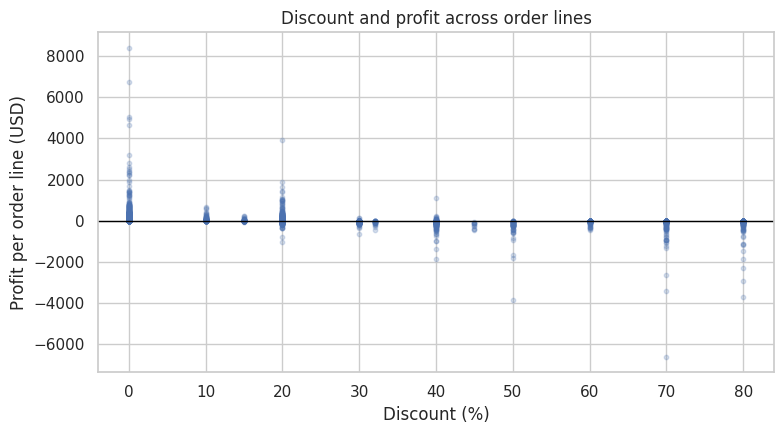

In [8]:
plt.figure(figsize=(8, 4.5))
plt.scatter(df["Discount (%)"], df["Profit"], alpha=0.22, s=10)
plt.axhline(0, color="black", linewidth=1)
plt.xlabel("Discount (%)")
plt.ylabel("Profit per order line (USD)")
plt.title("Discount and profit across order lines")

plt.tight_layout()
plt.show()

#Count plot · Shipping mode by segment

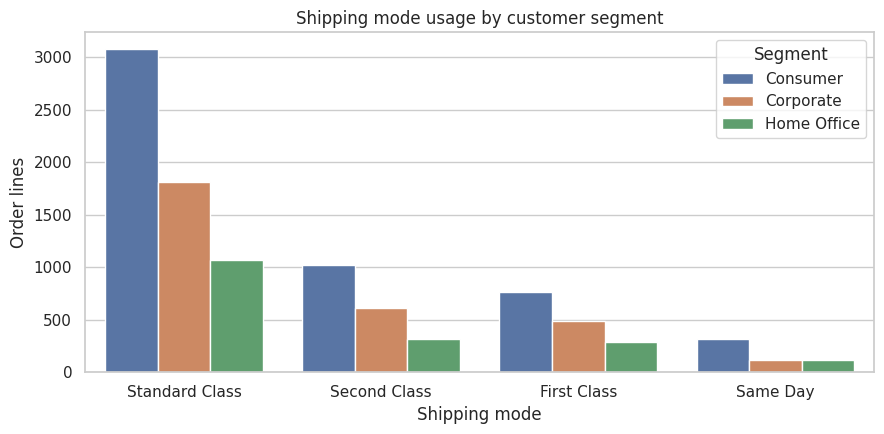

In [9]:
plt.figure(figsize=(9, 4.5))
sns.countplot(data=df, x="Ship Mode", hue="Segment",
              order=df["Ship Mode"].value_counts().index)
plt.xlabel("Shipping mode")
plt.ylabel("Order lines")
plt.title("Shipping mode usage by customer segment")

plt.tight_layout()
plt.show()

#Box plot · Profit by discount band

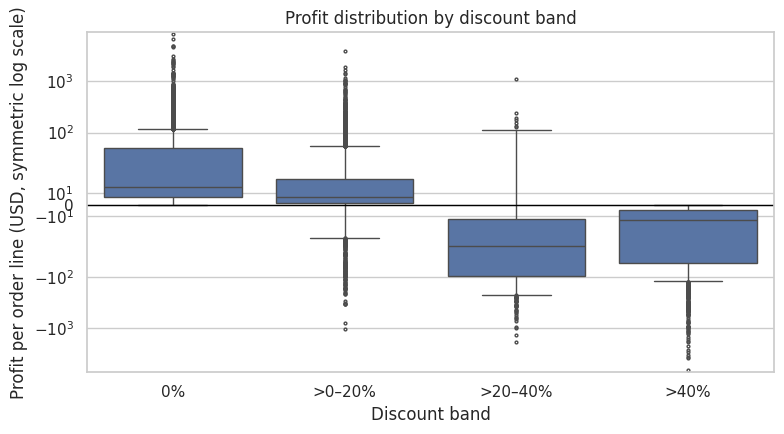

In [10]:
plt.figure(figsize=(8, 4.5))
sns.boxplot(data=df, x="Discount Band", y="Profit", fliersize=2)
plt.axhline(0, color="black", linewidth=1)
plt.yscale("symlog", linthresh=50)
plt.xlabel("Discount band")
plt.ylabel("Profit per order line (USD, symmetric log scale)")
plt.title("Profit distribution by discount band")

plt.tight_layout()
plt.show()

#Violin · Shipping days by mode

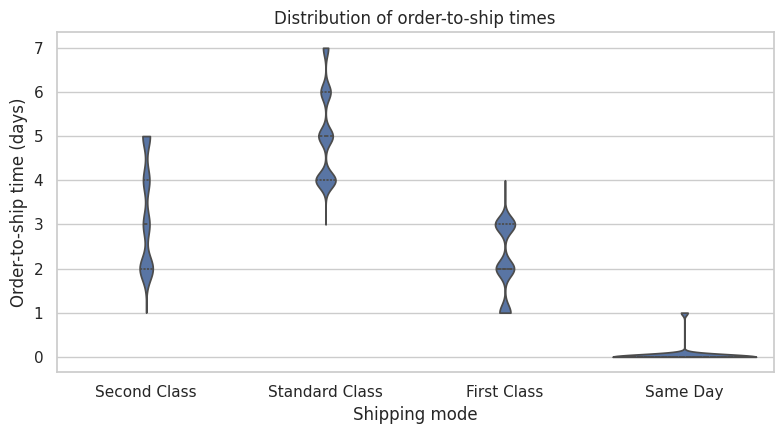

In [11]:
plt.figure(figsize=(8, 4.5))
sns.violinplot(data=df, x="Ship Mode", y="Shipping Days", inner="quartile", cut=0)
plt.xlabel("Shipping mode")
plt.ylabel("Order-to-ship time (days)")
plt.title("Distribution of order-to-ship times")

plt.tight_layout()
plt.show()

#Strip · Profit by regional market

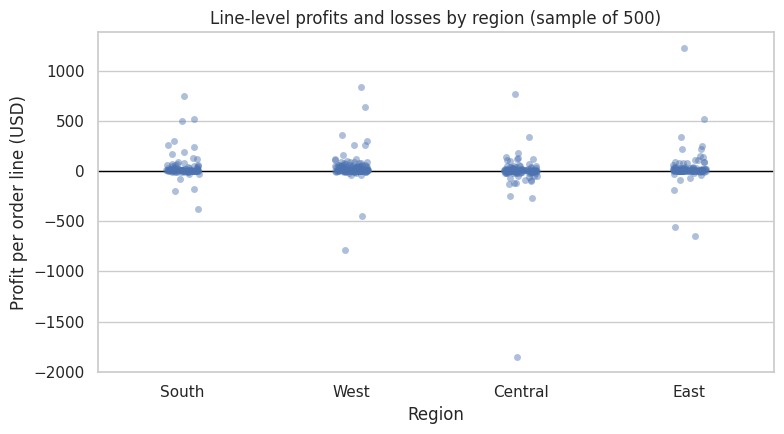

In [12]:
profit_sample = df.sample(n=500, random_state=42)
plt.figure(figsize=(8, 4.5))
sns.stripplot(data=profit_sample, x="Region", y="Profit", jitter=True, alpha=0.45)
plt.axhline(0, color="black", linewidth=1)
plt.xlabel("Region")
plt.ylabel("Profit per order line (USD)")
plt.title("Line-level profits and losses by region (sample of 500)")

plt.tight_layout()
plt.show()

#Swarm · Basket size by segment

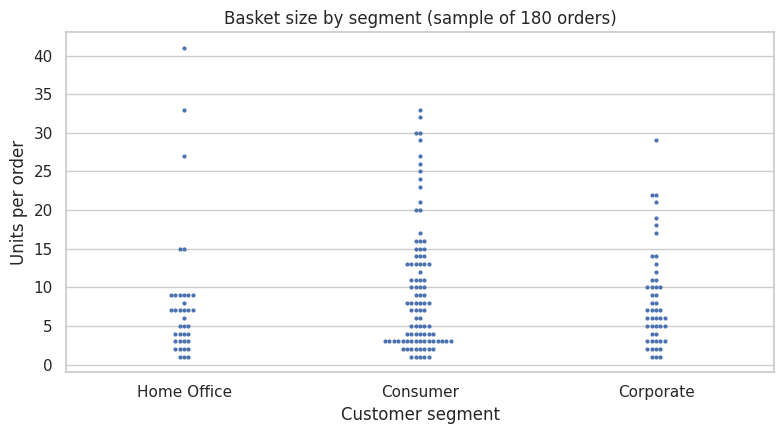

In [13]:
baskets = df.groupby(["Order ID", "Segment"], as_index=False)["Quantity"].sum()
basket_sample = baskets.sample(n=180, random_state=42)
plt.figure(figsize=(8, 4.5))
sns.swarmplot(data=basket_sample, x="Segment", y="Quantity", size=3)
plt.xlabel("Customer segment")
plt.ylabel("Units per order")
plt.title("Basket size by segment (sample of 180 orders)")

plt.tight_layout()
plt.show()

#Pie · Share of sales by segment

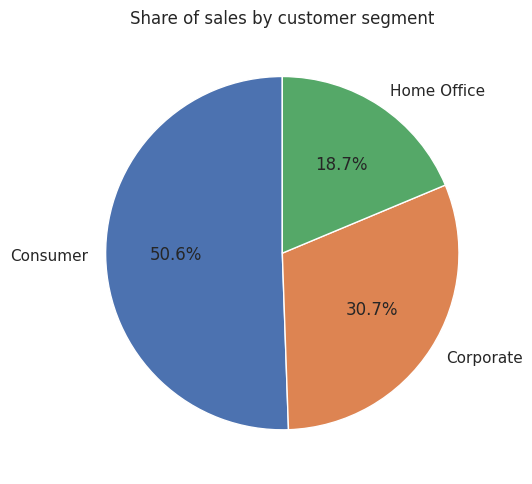

In [14]:
segment_sales = df.groupby("Segment")["Sales"].sum()
plt.figure(figsize=(7, 5))
plt.pie(segment_sales, labels=segment_sales.index, autopct="%1.1f%%", startangle=90)
plt.title("Share of sales by customer segment")

plt.tight_layout()
plt.show()

#Heatmap · Profit margin by region and segment

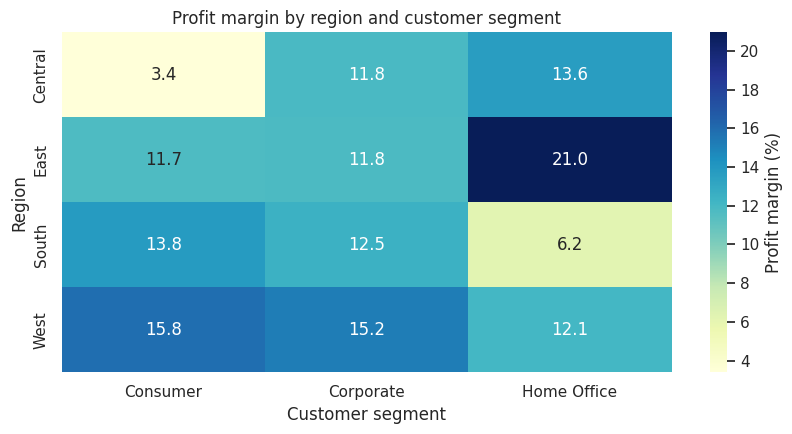

In [15]:
totals = df.groupby(["Region", "Segment"])[["Sales", "Profit"]].sum()
margins = (100 * totals["Profit"] / totals["Sales"]).unstack()
plt.figure(figsize=(8.5, 4.5))
sns.heatmap(margins, annot=True, fmt=".1f", cmap="YlGnBu",
            cbar_kws={"label": "Profit margin (%)"})
plt.xlabel("Customer segment")
plt.ylabel("Region")
plt.title("Profit margin by region and customer segment")

plt.tight_layout()
plt.show()

#Quiver · Regional sales and profit movement

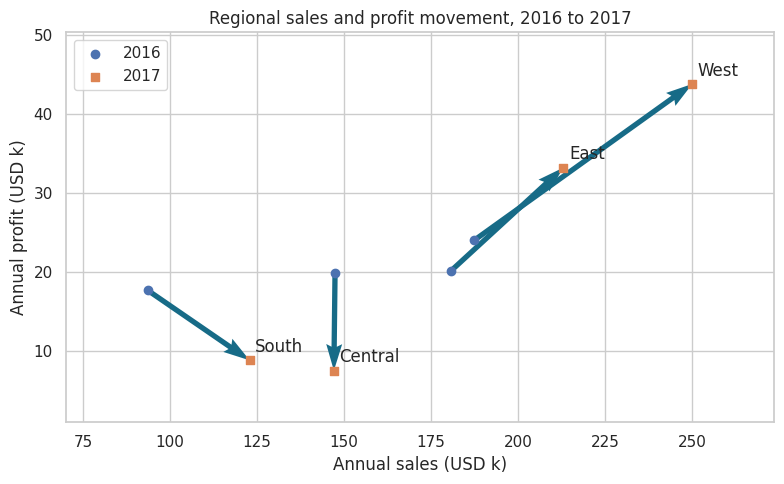

In [16]:
annual = df.groupby([df["Order Date"].dt.year.rename("Year"), "Region"])[["Sales", "Profit"]].sum() / 1000
previous_year, latest_year = sorted(annual.index.get_level_values("Year").unique())[-2:]
start = annual.loc[previous_year]
change = annual.loc[latest_year].reindex(start.index) - start
fig, ax = plt.subplots(figsize=(8, 5))
ax.quiver(start["Sales"], start["Profit"], change["Sales"], change["Profit"],
          angles="xy", scale_units="xy", scale=1, color="#176B87")
ax.scatter(start["Sales"], start["Profit"], label=str(previous_year))
end = start + change
ax.scatter(end["Sales"], end["Profit"], marker="s", label=str(latest_year))
for region in end.index:
    ax.annotate(region, end.loc[region], xytext=(4, 6), textcoords="offset points")
ax.margins(x=0.15, y=0.18)
ax.set(xlabel="Annual sales (USD k)", ylabel="Annual profit (USD k)",
       title=f"Regional sales and profit movement, {previous_year} to {latest_year}")
ax.legend()

plt.tight_layout()
plt.show()

#Contour · Average profit by quantity and discount

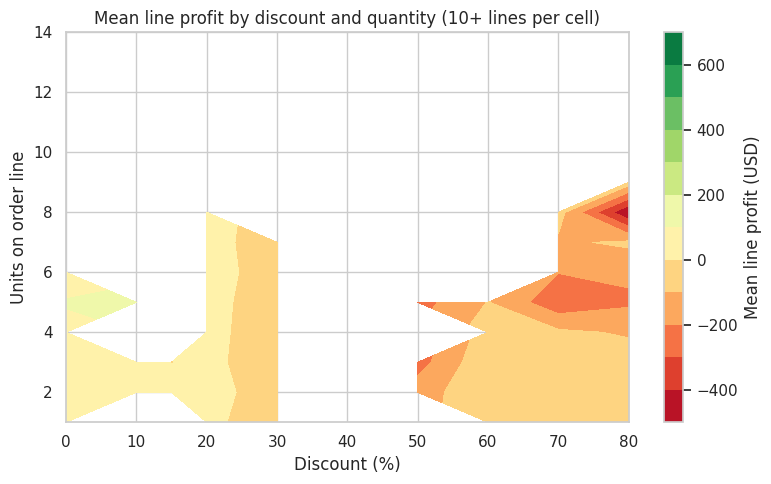

In [17]:
grid = df.pivot_table(index="Quantity", columns="Discount (%)", values="Profit", aggfunc="mean")
counts = df.pivot_table(index="Quantity", columns="Discount (%)", values="Profit",
                        aggfunc="size", fill_value=0)
grid = grid.where(counts >= 10)
discount_grid, quantity_grid = np.meshgrid(grid.columns, grid.index)
plt.figure(figsize=(8, 5))
contours = plt.contourf(discount_grid, quantity_grid, grid.to_numpy(),
                        levels=12, cmap="RdYlGn")
plt.colorbar(contours, label="Mean line profit (USD)")
plt.xlabel("Discount (%)")
plt.ylabel("Units on order line")
plt.title("Mean line profit by discount and quantity (10+ lines per cell)")

plt.tight_layout()
plt.show()

#· Annotated subplots · Sub-category losses

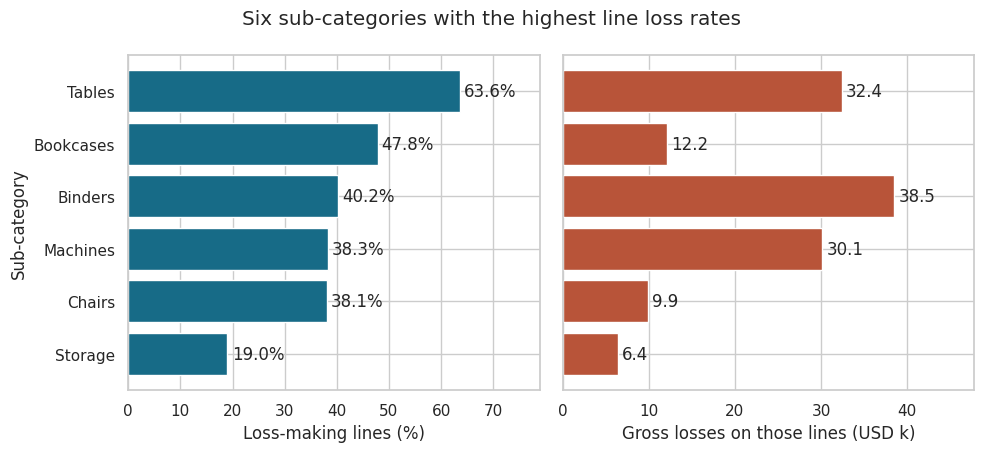

In [18]:
loss_rate = 100 * df.groupby("Sub-Category")["Loss"].mean()
worst = loss_rate.nlargest(6).sort_values()
loss_value = -df.loc[df["Loss"]].groupby("Sub-Category")["Profit"].sum()
loss_value = loss_value.reindex(worst.index, fill_value=0) / 1000
fig, axes = plt.subplots(1, 2, figsize=(10, 4.6), sharey=True)
rates = axes[0].barh(worst.index, worst, color="#176B87")
losses = axes[1].barh(worst.index, loss_value, color="#B85439")
axes[0].bar_label(rates, fmt="%.1f%%", padding=3)
axes[1].bar_label(losses, fmt="%.1f", padding=3)
axes[0].set(xlabel="Loss-making lines (%)", ylabel="Sub-category",
            xlim=(0, worst.max() * 1.24))
axes[1].set(xlabel="Gross losses on those lines (USD k)",
            xlim=(0, loss_value.max() * 1.24))
fig.suptitle("Six sub-categories with the highest line loss rates")

plt.tight_layout()
plt.show()

In [19]:
from pathlib import Path
import numpy as np
import pandas as pd

csv_path = Path("Sample - Superstore.csv")
if not csv_path.is_file():
    raise FileNotFoundError("Upload Sample - Superstore.csv using the Colab Files panel.")
raw = pd.read_csv(csv_path, encoding="cp1252", dtype={"Postal Code": "string"})
print(f"Loaded {raw.shape[0]:,} order lines and {raw.shape[1]} columns.")

Loaded 9,994 order lines and 21 columns.


#Variables, types and operators

In [20]:
sales = float(raw.loc[0, "Sales"])
quantity = int(raw.loc[0, "Quantity"])
profit = float(raw.loc[0, "Profit"])
category = raw.loc[0, "Category"]
print(sales, quantity, profit, category)

261.96 2 41.9136 Furniture


#Identify integer, float, string and Boolean types

In [21]:
is_profitable = profit > 0
for value in (quantity, sales, category, is_profitable):
    print(value, type(value).__name__)

2 int
261.96 float
Furniture str
True bool


#Divide sales by quantity to estimate line sales per unit

In [22]:
unit_sales = sales / quantity
print(f"Recorded sales per unit: USD {unit_sales:,.2f}")

Recorded sales per unit: USD 130.98


#Multiply unit sales by quantity and check the result

In [23]:
reconstructed_sales = unit_sales * quantity
print(f"Reconstructed line sales: USD {reconstructed_sales:,.2f}")
print("Matches recorded sales:", np.isclose(reconstructed_sales, sales))

Reconstructed line sales: USD 261.96
Matches recorded sales: True


#Subtract profit from sales to calculate implied cost

In [24]:
implied_cost = sales - profit
print(f"Implied cost for this line: USD {implied_cost:,.2f}")

Implied cost for this line: USD 220.05


#Use if and else to flag a loss

In [25]:
if profit < 0:
    print("Loss-making line")
else:
    print("Non-loss-making line")

Non-loss-making line


#Inspect dataset structure with info()

In [26]:
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9994 non-null   string 
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 non-null   float64
 18  Quantity

#Find the ten largest line losses

In [27]:
display(raw.nsmallest(10, "Profit")[["Product Name", "Category", "Discount", "Profit"]])

,Product Name,Category,Discount,Profit
7772,Cubify CubeX 3D Printer Double Head Print,Technology,0.7,-6599.9780
683,Cubify CubeX 3D Printer Triple Head Print,Technology,0.5,-3839.9904
9774,GBC DocuBind P400 Electric Binding System,Office Supplies,0.8,-3701.8928
3011,Lexmark MX611dhe Monochrome Laser Printer,Technology,0.7,-3399.9800
4991,Ibico EPK-21 Electric Binding System,Office Supplies,0.8,-2929.4845
3151,Cubify CubeX 3D Printer Double Head Print,Technology,0.7,-2639.9912
5310,Fellowes PB500 Electric Punch Plastic Comb Bin...,Office Supplies,0.8,-2287.7820
9639,Chromcraft Bull-Nose Wood Oval Conference Tabl...,Furniture,0.4,-1862.3124
1199,GBC DocuBind P400 Electric Binding System,Office Supplies,0.8,-1850.9464
2697,Cisco TelePresence System EX90 Videoconferenci...,Technology,0.5,-1811.0784


#Loop through selected records with for and range

In [29]:
for position in range(5):
    row = raw.iloc[position]
    print(row["Row ID"], row["Category"], f"USD {row['Sales']:,.2f}")

1 Furniture USD 261.96
2 Furniture USD 731.94
3 Office Supplies USD 14.62
4 Furniture USD 957.58
5 Office Supplies USD 22.37


#Build a dictionary of line counts by region

In [30]:
lines_by_region = {}
for region in raw["Region"]:
    lines_by_region[region] = lines_by_region.get(region, 0) + 1
print(lines_by_region)

{'South': 1620, 'West': 3203, 'Central': 2323, 'East': 2848}


#EDA, data types and descriptive statistics

In [31]:
print("Shape:", raw.shape)
print("Columns:", raw.columns.tolist())
print("Index:", raw.index)

Shape: (9994, 21)
Columns: ['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']
Index: RangeIndex(start=0, stop=9994, step=1)


#Count and calculate missing values by column

In [32]:
missing = pd.DataFrame({
    "Missing count": raw.isna().sum(),
    "Missing share (%)": raw.isna().mean().mul(100),
})
display(missing)

,Missing count,Missing share (%)
Row ID,0,0.0
Order ID,0,0.0
Order Date,0,0.0
Ship Date,0,0.0
Ship Mode,0,0.0
Customer ID,0,0.0
Customer Name,0,0.0
Segment,0,0.0
Country,0,0.0
City,0,0.0


#Compare sales, profit and weighted margin by category

In [34]:
category_summary = df.groupby("Category").agg(
    Sales=("Sales", "sum"), Profit=("Profit", "sum"),
    Order_Lines=("Row ID", "size"), Orders=("Order ID", "nunique"),
)
category_summary["Margin (%)"] = 100 * category_summary["Profit"] / category_summary["Sales"]
display(category_summary.sort_values("Sales", ascending=False).round(2))

,Sales,Profit,Order_Lines,Orders,Margin (%)
Category,,,,,
Technology,836154.03,145454.95,1847,1544,17.40
Furniture,741999.80,18451.27,2121,1764,2.49
Office Supplies,719047.03,122490.80,6026,3742,17.04


#Statistics and regression

In [36]:
measure_columns = ["Sales", "Profit", "Discount", "Quantity"]
numeric = df[measure_columns]
statistics = pd.DataFrame({
    "Variance": numeric.var(), "Std. dev.": numeric.std(),
    "Q1": numeric.quantile(0.25), "Median": numeric.median(), "Q3": numeric.quantile(0.75),
})
display(statistics.round(4))

,Variance,Std. dev.,Q1,Median,Q3
Sales,388434.4553,623.2451,17.2800,54.4900,209.940
Profit,54877.7981,234.2601,1.7288,8.6665,29.364
Discount,0.0426,0.2065,0.0000,0.2000,0.200
Quantity,4.9511,2.2251,2.0000,3.0000,5.000


#Check which variables contribute most to each component

In [38]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Define variables for PCA analysis
pca_features = ["Sales", "Profit", "Discount", "Quantity"]
x = df[pca_features]

# Scale the features to have mean=0 and variance=1
x_scaled = StandardScaler().fit_transform(x)

# Fit PCA
pca = PCA(n_components=len(pca_features))
pca.fit(x_scaled)

# Create index/columns for visualization
explained_index = [f"PC{i+1}" for i in range(len(pca_features))]
explained = pd.Series(pca.explained_variance_ratio_, index=explained_index)

# Calculate and display feature weights
weights = pd.DataFrame(pca.components_.T, index=pca_features, columns=explained.index)
display(weights.round(3))
display(weights.abs().idxmax().rename("Largest absolute weight"))

,PC1,PC2,PC3,PC4
Sales,0.643,0.218,-0.306,-0.667
Profit,0.655,-0.195,-0.253,0.684
Discount,-0.270,0.719,-0.592,0.245
Quantity,0.289,0.631,0.701,0.163


,Largest absolute weight
PC1,Profit
PC2,Discount
PC3,Quantity
PC4,Profit


In [40]:
from google.colab import files
files.download("Superstore_Cleaned.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>